<a href="https://colab.research.google.com/github/mariaaapetrovskaya/compling_nlp_course/blob/main/05_homework_harness_benchmarks_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Задание 1 (8 баллов + 0.5)

Скачайте вот этот датасет - ("MERA-evaluation/MERA", "multiq"). Так как обучать ничего не придется возьмите train split. Возьмите оттуда 25 примеров (случайных, а не первых).

Преобразуйте колонку instruction, заменив переменные вроде `{support_text}` на реальные значения из других колонок, чтобы получился готовый промпт (инпут для модели).

#### Метрика (2 балла)

Напишите две метрики для оценки правильных ответов: 1) exact match и 2) F1 по леммам. Для первой просто добавьте базовую предобработку вроде удаления пунктуации и регистра и просто сопоставьте строки между собой. Для второй к базовой предобработке добавьте токенизацию и лемматизацию, а поверх лемм рассчитайте F1 метрику (подсказка - precision можно рассчитать посчитав какой процент лемм в предсказанном ответе совпадает с правильным ответом).

Рассчитайте метрики на простом бейзлайне (например, можете попробовать взять самый частотный биграмм из промпта в качестве ответа). Можно получить +0.5 балла за неочевидный ненулевой бейзлайн.

#### Эксперимент 1 (2 балла)
Возьмите какую-нибудь не очень большую модель с huggingface (например, `Qwen/Qwen3.5-0.8B`, но можно и любую другую, которая умеет отвечать на инструкции и поддерживает thinking). Преобразуйте промпты из датасета в формат `messages = [{"role": "user", "content": prompt}]` с помощью чат темплейта этой модели.
Сгенерируйте ответы модели на полученных данных (25 примеров). На этом шаге не используйте thinking. Поставьте max_new_tokens на не очень большое значения, чтобы генерация не занимала слишком много времени.
Оцените качество ответов с помощью двух метрик.

#### Эксперимент 2 (1 балла)
К первому эксперименту добавьте какой-то system prompt, который по вашему должен помочь модели справится с результатом. Можете проанализировать ошибки из первого задания и написать инструкции на основе этого.
Сгенерируйте ответы с точно такими же параметрами как и в эксперименте 1.
Оцените качество ответов с помощью двух метрик.

#### Эсперимент 3 (3 балла)
На этом шаге включите thinking в модели и сгенерируйте предсказания (system prompt вы можете использовать по вашему желанию).
На этом шаге у вас будет несколько сложностей, которые нужно решить:
1) генерацию модели нельзя использовать напрямую, сначала нужно отделить thinking блок от самого ответа. Добавьте пост обработку
2) thinking может занять достаточно много токенов и его нужно ограничить, но при этом вам нужно, чтобы модель выдала и сам ответ, а не только незаконченные размышлений. Выберите max_new_tokens с рассчетом на (thinking_tokens + answer_tokens). Сначала запустите первую генерацию с thinking_tokens, затем проверьте, что в ответе содержится </think> тэг, который означает, что модель закончила думать (еще удобно использовать `stop_strings` в huggingface generation параметрах, чтобы заканчивать как только появился нужный токен). И если тэг есть, то просто запустите вторую генерацию с max_new_tokens (как продолжение уже накопившегося) или же поставьте </think> тэг вручную (обрубив размышление) и запустите вторую генерацию c answer_tokens.


In [12]:

!pip -q install -U datasets transformers accelerate pymorphy3


In [13]:

import re
import string
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from collections import Counter
from string import Formatter
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
import pymorphy3

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

dataset = load_dataset("MERA-evaluation/MERA", "multiq")

print(dataset)
print("Колонки:", dataset["train"].column_names)
print("Пример:", dataset["train"][0])


DatasetDict({
    train: Dataset({
        features: ['instruction', 'inputs', 'outputs', 'meta'],
        num_rows: 1056
    })
    test: Dataset({
        features: ['instruction', 'inputs', 'outputs', 'meta'],
        num_rows: 900
    })
})
Колонки: ['instruction', 'inputs', 'outputs', 'meta']
Пример: {'instruction': 'Даны два текста:\nТекст 1: {support_text}\nТекст 2: {text}\nОпираясь на данные тексты, ответьте на вопрос: {question}\nВаш ответ не должен содержать дополнительные объяснения.\nОтвет:', 'inputs': {'text': 'Нижний Новгород (в разговорной речи часто — "Нижний", c XIII по XVII век — Новгород Низовской земли, с 7 октября 1932 по 22 октября 1990 года — Горький) — город в центральной России, административный центр Приволжского федерального округа и Нижегородской области. Второй по численности населения город в Приволжском федеральном округе и на реке Волге.\\n\\nКультура.\\nИсторический центр Нижнего Новгорода, расположенный в Нагорной части города, несмотря на значительные

In [14]:

train_data = dataset["train"]

assert len(train_data) >= 25

sample = train_data.shuffle(seed=SEED).select(range(25))


def build_prompt(example):
    instruction = example["instruction"]
    inputs = example["inputs"]

    if not isinstance(inputs, dict):
        raise TypeError(
            f"Ожидался словарь inputs, получено: {type(inputs)}"
        )

    fields = [
        field
        for _, field, _, _ in Formatter().parse(instruction)
        if field is not None
    ]

    missing = [field for field in fields if field not in inputs]

    if missing:
        raise KeyError(
            f"В inputs отсутствуют переменные {missing}. "
            f"Доступные поля: {list(inputs.keys())}"
        )

    prompt = instruction.format(**inputs)

    if re.search(r"\{[^{}]+\}", prompt):
        raise ValueError(
            f"Остались незаменённые переменные: {prompt}"
        )

    return prompt


def format_reference(output):
    if isinstance(output, (list, tuple)):
        return ";".join(str(x).strip() for x in output)
    return str(output).strip()


examples = []

for i, example in enumerate(sample):
    examples.append({
        "sample_id": i,
        "prompt": build_prompt(example),
        "reference": format_reference(example["outputs"])
    })

df = pd.DataFrame(examples)

assert len(df) == 25
assert df["prompt"].notna().all()
assert df["reference"].notna().all()

print("Количество примеров:", len(df))
print("\nПромпт:")
print(df.loc[0, "prompt"])
print("\nЭталонный ответ:")
print(df.loc[0, "reference"])

df.to_csv("multiq_sample_25.csv", index=False, encoding="utf-8-sig")


Количество примеров: 25

Промпт:
Найдите в приведенных двух текстах ответ на заданный вопрос и выпишите этот ответ. Он должен являться словом или короткой фразой, дополнительные объяснения приводить не нужно.
Текст 1: Мурдюг (Большой Мурдюг) — река в России, протекает в Оричевском районе Кировской области. Устье реки находится в 494 км по левому берегу реки Вятки. Длина реки составляет 21 км. В 1,8 километрах от устья принимает слева реку Тумана.\n\nДанные водного реестра.\nПо данным государственного водного реестра России относится к Камскому бассейновому округу, водохозяйственный участок реки — Вятка от города Котельнич до водомерного поста посёлка городского типа Аркуль, речной подбассейн реки — Вятка. Речной бассейн реки — Кама.
Текст 2: Вятка ( , , ) — река в Европейской части России, крупнейший правый приток Камы (бассейн Волги) и второй по величине после Белой. Длина реки — 1314 км, площадь водосборного бассейна — 129 000 кв км.\n\nГеография.\nСхема бассейна Вятки. Начинается на

In [15]:

morph = pymorphy3.MorphAnalyzer()


def normalize_text(text):
    text = str(text).lower()

    text = re.sub(r"[^\w\s]", "", text, flags=re.UNICODE)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def split_references(reference):
    if isinstance(reference, (list, tuple)):
        answers = reference
    else:
        answers = str(reference).split(";")

    return [
        str(answer).strip()
        for answer in answers
        if str(answer).strip()
    ]


def exact_match(prediction, reference):
    pred = normalize_text(prediction)

    return float(any(
        pred == normalize_text(ref)
        for ref in split_references(reference)
    ))


def lemmatize_tokens(text):
    tokens = re.findall(
        r"\w+", normalize_text(text), flags=re.UNICODE
    )

    lemmas = []

    for token in tokens:
        if token.isalpha() and re.search(r"[а-яё]", token):
            lemmas.append(morph.parse(token)[0].normal_form)
        else:

            lemmas.append(token)

    return lemmas


def lemma_f1_single(prediction, reference):
    pred = Counter(lemmatize_tokens(prediction))
    ref = Counter(lemmatize_tokens(reference))

    if not pred and not ref:
        return 1.0

    if not pred or not ref:
        return 0.0

    common = sum((pred & ref).values())

    precision = common / sum(pred.values())
    recall = common / sum(ref.values())

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


def lemma_f1(prediction, reference):
    references = split_references(reference)

    if not references:
        return float(not lemmatize_tokens(prediction))

    return max(
        lemma_f1_single(prediction, ref)
        for ref in references
    )


def evaluate(predictions, references):
    assert len(predictions) == len(references)

    return {
        "Exact Match": float(np.mean([
            exact_match(p, r)
            for p, r in zip(predictions, references)
        ])),
        "Lemma F1": float(np.mean([
            lemma_f1(p, r)
            for p, r in zip(predictions, references)
        ]))
    }


In [16]:

def most_frequent_bigram_baseline(prompt):
    tokens = re.findall(
        r"\w+", normalize_text(prompt), flags=re.UNICODE
    )

    bigrams = list(zip(tokens, tokens[1:]))

    if not bigrams:
        return ""

    counts = Counter(bigrams)
    max_count = max(counts.values())


    best_bigram = next(
        bigram for bigram in bigrams
        if counts[bigram] == max_count
    )

    return " ".join(best_bigram)


baseline_predictions = [
    most_frequent_bigram_baseline(prompt)
    for prompt in df["prompt"]
]

baseline_metrics = evaluate(
    baseline_predictions,
    df["reference"].tolist()
)

df["baseline_prediction"] = baseline_predictions

print("Метрики бейзлайна:")
print(pd.Series(baseline_metrics))


Метрики бейзлайна:
Exact Match    0.00
Lemma F1       0.04
dtype: float64


Эксперимент 1

In [17]:

MODEL_NAME = "Qwen/Qwen3.5-0.8B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Устройство модели:", model.device)


def make_model_input(
    prompt,
    system_prompt=None,
    enable_thinking=False
):
    messages = []

    if system_prompt is not None:
        messages.append({
            "role": "system",
            "content": system_prompt
        })

    messages.append({
        "role": "user",
        "content": prompt
    })

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=enable_thinking
    )


MAX_NEW_TOKENS = 128


@torch.inference_mode()
def generate_answer(prompt, system_prompt=None):
    formatted_prompt = make_model_input(
        prompt,
        system_prompt=system_prompt,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(model.device)

    output_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    new_tokens = output_ids[
        0, inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()


predictions_exp1 = []

for i, prompt in enumerate(df["prompt"]):
    prediction = generate_answer(prompt)
    predictions_exp1.append(prediction)

    print(f"\n[{i + 1}/25]")
    print("Предсказание:", prediction)
    print("Эталон:", df.loc[i, "reference"])

metrics_exp1 = evaluate(
    predictions_exp1,
    df["reference"].tolist()
)

df["prediction_exp1"] = predictions_exp1

print("\nЭксперимент 1:")
print(pd.Series(metrics_exp1))


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Устройство модели: cuda:0


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.



[1/25]
Предсказание: Тумана
Эталон: Каму;Камы

[2/25]
Предсказание: Глава государства, ставшего местом смерти Романа Николаевича Филипова, — это **Сирия**.

**Пояснение:**
В тексте первого предложения указано, что Роман Николаевич Филипов погиб в Сирийской Арабской Республике (Сирия). Текст второго предложения также содержит полное наименование этого государства: «Сирийская Арабская Республика ( «аль-Джумхурийя аль-Арабийя ас-Сурийя») — государство на Ближнем Востоке...». Таким образом, ответ на вопрос «Что за должность» (в данном контексте — государство)
Эталон: президентов

[3/25]
Предсказание: 4506 м
Эталон: Белуха;гора Белуха

[4/25]
Предсказание: Суходревка впадает в реку Суходрев.
Эталон: Шаня

[5/25]
Предсказание: Ереванский городский совет
Эталон: ереванским городским советом

[6/25]
Предсказание: Ворговаш.
Эталон: Сабля

[7/25]
Предсказание: Лига МХ
Эталон: Лиге МХ

[8/25]
Предсказание: Ереван
Эталон: Ереван

[9/25]
Предсказание: Министр иностранных дел
Эталон: президентов

[

Эксперимент 2 (системн промпи)

In [18]:

SYSTEM_PROMPT = (
    "Ответь на вопрос, используя предоставленный контекст. "
    "Внимательно различай сведения из контекста и сам вопрос. "
    "Дай конкретный ответ, который соответствует инструкции. "
    "Не придумывай отсутствующие факты. "
    "Не добавляй вступление и пояснения, если они не нужны "
    "для ответа. Соблюдай указанный формат ответа."
)


predictions_exp2 = []

for i, prompt in enumerate(df["prompt"]):
    prediction = generate_answer(
        prompt,
        system_prompt=SYSTEM_PROMPT
    )

    predictions_exp2.append(prediction)

    print(f"\n[{i + 1}/25]")
    print("Предсказание:", prediction)
    print("Эталон:", df.loc[i, "reference"])

metrics_exp2 = evaluate(
    predictions_exp2,
    df["reference"].tolist()
)

df["prediction_exp2"] = predictions_exp2

print("\nЭксперимент 2:")
print(pd.Series(metrics_exp2))



[1/25]
Предсказание: Тумана
Эталон: Каму;Камы

[2/25]
Предсказание: Глава государства, ставшего местом смерти Романа Николаевича Филипова, — это Сирия.
Эталон: президентов

[3/25]
Предсказание: Гора Белуха
Эталон: Белуха;гора Белуха

[4/25]
Предсказание: Суходревка впадает в реку Суходрев.
Эталон: Шаня

[5/25]
Предсказание: Ереванский городский совет
Эталон: ереванским городским советом

[6/25]
Предсказание: Ворговаш — река в России, протекает на северо-западе Переславского района Ярославской области; правый приток реки Кисьма.
Эталон: Сабля

[7/25]
Предсказание: Лига МХ
Эталон: Лиге МХ

[8/25]
Предсказание: Ереван
Эталон: Ереван

[9/25]
Предсказание: Министр иностранных дел
Эталон: президентов

[10/25]
Предсказание: Евгений Тефтелев
Эталон: Евгению Тефтелеву

[11/25]
Предсказание: Ереванский городский совет
Эталон: городским советом

[12/25]
Предсказание: Зеленоград
Эталон: Зеленоградский административный округ

[13/25]
Предсказание: Ереванское городское совет
Эталон: ереванским горо

Эксперимент 3 с thinking

In [19]:

THINKING_TOKENS = 256
ANSWER_TOKENS = 64

THINK_END = "</think>"

think_end_ids = tokenizer.encode(
    THINK_END,
    add_special_tokens=False
)

im_end_ids = tokenizer.encode(
    "<|im_end|>",
    add_special_tokens=False
)


def find_subsequence(sequence, subsequence):
    if not subsequence:
        return -1

    for i in range(len(sequence) - len(subsequence) + 1):
        if sequence[i:i + len(subsequence)] == subsequence:
            return i

    return -1


@torch.inference_mode()
def generate_with_thinking(prompt, system_prompt=None):
    formatted_prompt = make_model_input(
        prompt,
        system_prompt=system_prompt,
        enable_thinking=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(model.device)


    first_output = model.generate(
        **inputs,
        max_new_tokens=THINKING_TOKENS,
        do_sample=True,
        temperature=0.6,
        top_p=0.95,
        top_k=20,
        pad_token_id=tokenizer.eos_token_id
    )

    input_length = inputs["input_ids"].shape[1]
    generated_ids = first_output[0, input_length:].tolist()

    end_position = find_subsequence(
        generated_ids,
        think_end_ids
    )

    if end_position >= 0:

        generated_ids = generated_ids[
            :end_position + len(think_end_ids)
        ]
    else:

        while generated_ids:
            last_token = generated_ids[-1]

            is_eos = (
                tokenizer.eos_token_id is not None
                and last_token == tokenizer.eos_token_id
            )

            is_im_end = (
                bool(im_end_ids)
                and len(generated_ids) >= len(im_end_ids)
                and generated_ids[-len(im_end_ids):] == im_end_ids
            )

            if is_eos:
                generated_ids.pop()
            elif is_im_end:
                del generated_ids[-len(im_end_ids):]
            else:
                break


        generated_ids.extend(think_end_ids)

    continuation = torch.tensor(
        [generated_ids],
        dtype=inputs["input_ids"].dtype,
        device=model.device
    )

    full_input_ids = torch.cat(
        [inputs["input_ids"], continuation],
        dim=1
    )

    attention_mask = torch.ones_like(full_input_ids)


    second_output = model.generate(
        input_ids=full_input_ids,
        attention_mask=attention_mask,
        max_new_tokens=ANSWER_TOKENS,
        do_sample=True,
        temperature=0.6,
        top_p=0.95,
        top_k=20,
        pad_token_id=tokenizer.eos_token_id
    )

    all_generated_ids = second_output[0, input_length:]

    raw_text = tokenizer.decode(
        all_generated_ids,
        skip_special_tokens=False
    )


    if THINK_END in raw_text:
        answer = raw_text.rsplit(THINK_END, 1)[1].strip()
    else:
        answer = raw_text.strip()


    answer = answer.replace("<|im_end|>", "").strip()
    answer = answer.replace("<|endoftext|>", "").strip()

    return {
        "raw_generation": raw_text,
        "prediction": answer,
        "thinking_completed": end_position >= 0
    }


predictions_exp3 = []
raw_generations_exp3 = []
thinking_completed = []

for i, prompt in enumerate(df["prompt"]):
    result = generate_with_thinking(
        prompt,
        system_prompt=SYSTEM_PROMPT
    )

    predictions_exp3.append(result["prediction"])
    raw_generations_exp3.append(result["raw_generation"])
    thinking_completed.append(result["thinking_completed"])

    print(f"\n[{i + 1}/25]")
    print("Ответ:", result["prediction"])
    print(
        "Тег thinking найден в бюджете:",
        result["thinking_completed"]
    )

metrics_exp3 = evaluate(
    predictions_exp3,
    df["reference"].tolist()
)

df["prediction_exp3"] = predictions_exp3
df["raw_generation_exp3"] = raw_generations_exp3
df["thinking_completed"] = thinking_completed

print("\nЭксперимент 3:")
print(pd.Series(metrics_exp3))
print(
    "Число примеров с найденным </think>:",
    sum(thinking_completed),
    "из",
    len(thinking_completed)
)



[1/25]
Ответ: the prompt text: "В какую реку впадает река, притоком которой является Мурдюг?" Wait, there's a specific phrasing in the prompt: "В какую реку впадает река, притоком которой является Мурдюг?" No, looking closely at the user input: "
Тег thinking найден в бюджете: False

[2/25]
Ответ: ) and Text 2 (Geography).
    *   Question: Who is the person who became the place of death of Roman Nikolayevich Filippov?
    *   Wait, the question asks: "What position does the head of state, who became the place of death of Roman Nikolay
Тег thinking найден в бюджете: False

[3/25]
Ответ: ... Казахстаном (Восточно-Казахстанская область) и Россией (Республика Алтай)."
        *   *Wait, there's a typo in the prompt text provided by the user.*
        *   "Текст 1: Холзун — горный хребет на
Тег thinking найден в бюджете: False

[4/25]
Ответ: " (Suhoдревka).
        *   Location: Kalyushsky area of Russia (Kaluzhsky district).
        *   Path: Flows in the Suhoдревka forest area.
        

         Эксперимент  Exact Match  Lemma F1
            Baseline         0.00  0.040000
1. Без system prompt         0.08  0.256000
  2. С system prompt         0.12  0.310889
       3. С thinking         0.00  0.023353


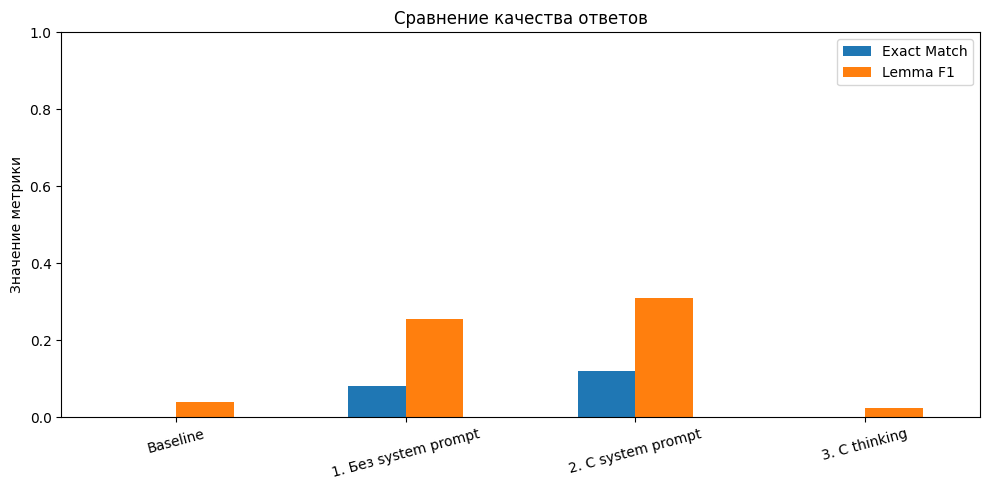

In [20]:

results = pd.DataFrame([
    {
        "Эксперимент": "Baseline",
        **baseline_metrics
    },
    {
        "Эксперимент": "1. Без system prompt",
        **metrics_exp1
    },
    {
        "Эксперимент": "2. С system prompt",
        **metrics_exp2
    },
    {
        "Эксперимент": "3. С thinking",
        **metrics_exp3
    }
])

print(results.to_string(index=False))


results_plot = results.set_index("Эксперимент")

results_plot[["Exact Match", "Lemma F1"]].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=15,
    title="Сравнение качества ответов"
)

plt.ylabel("Значение метрики")
plt.xlabel("")
plt.tight_layout()
plt.show()


In [21]:

comparison = df[
    [
        "sample_id",
        "reference",
        "baseline_prediction",
        "prediction_exp1",
        "prediction_exp2",
        "prediction_exp3"
    ]
].copy()

comparison["EM_exp1"] = [
    exact_match(p, r)
    for p, r in zip(
        comparison["prediction_exp1"],
        comparison["reference"]
    )
]

comparison["EM_exp2"] = [
    exact_match(p, r)
    for p, r in zip(
        comparison["prediction_exp2"],
        comparison["reference"]
    )
]

comparison["EM_exp3"] = [
    exact_match(p, r)
    for p, r in zip(
        comparison["prediction_exp3"],
        comparison["reference"]
    )
]

errors_exp2 = comparison[comparison["EM_exp2"] == 0]

print("Колво ошибок в эксперименте 2:", len(errors_exp2))
display(errors_exp2)

df.to_csv(
    "multiq_experiments_results.csv",
    index=False,
    encoding="utf-8-sig"
)

results.to_csv(
    "multiq_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Сохранены файлы:")
print("- multiq_sample_25.csv")
print("- multiq_experiments_results.csv")
print("- multiq_metrics.csv")


Колво ошибок в эксперименте 2: 22


,sample_id,reference,baseline_prediction,prediction_exp1,prediction_exp2,prediction_exp3,EM_exp1,EM_exp2,EM_exp3
0,0,Каму;Камы,река в,Тумана,Тумана,"the prompt text: ""В какую реку впадает река, п...",0.0,0.0,0.0
1,1,президентов,3 февраля,"Глава государства, ставшего местом смерти Рома...","Глава государства, ставшего местом смерти Рома...",) and Text 2 (Geography).\n * Question: W...,0.0,0.0,0.0
3,3,Шаня,река в,Суходревка впадает в реку Суходрев.,Суходревка впадает в реку Суходрев.,""" (Suhoдревka).\n * Location: Kalyush...",0.0,0.0,0.0
4,4,ереванским городским советом,гор шаваршевич,Ереванский городский совет,Ереванский городский совет,". Wait, let me read carefully. ""Гор Шаваршевич...",0.0,0.0,0.0
5,5,Сабля,река в,Ворговаш.,"Ворговаш — река в России, протекает на северо-...",Кисьма. Сельские населённые пункты около реки:...,0.0,0.0,0.0
6,6,Лиге МХ,лос кобос,Лига МХ,Лига МХ,(top division of the country). History section...,0.0,0.0,0.0
8,8,президентов,мухаммед ашави,Министр иностранных дел,Министр иностранных дел,"* Wait, I need to check the text provided.\n...",0.0,0.0,0.0
9,9,Евгению Тефтелеву,диана александровна,Борис Дубровский,Евгений Тефтелев,". (Wait, I need to check the exact spelling in...",0.0,0.0,0.0
10,10,городским советом,в городе,Ереван,Ереванский городский совет,(3 December 1961) and death date (1 January 19...,0.0,0.0,0.0
11,11,Зеленоградский административный округ,паре с,Город рождения Антиповой Юлии Валерьевны наход...,Зеленоград,"* Wait, I need to check the text content car...",0.0,0.0,0.0


Сохранены файлы:
- multiq_sample_25.csv
- multiq_experiments_results.csv
- multiq_metrics.csv


 включение thinking не улучшило качество ответов(